# **Block 05 assignment**: *neighbours for your towers*

**Name**: Ben Löw

**Matriculation nr.**: 5737500

**Tower sets student id**: 39

**GitHub fork**: https://github.com/loew-b/datascience_env_monit

**FLUXNET tower sites**:

| Site ID | Citation | Access date|
|---------|----------|------------|
| FR-Pue | Joffre, R., Limousin, J., Kempf, J., Ourcival, J., Piquemal, K., Veuillen, L. (2026). Fluxnet Archive Product from Puechabon, 2000-01-01–2026-09-06, FLUXNET, https://hdl.handle.net/11676/zX4eolqNe8xbcMScyT2IQ9XV | 2026-1120 |
| CA-Ca3 | T. Andrew Black (2026), AmeriFlux FLUXNET-1F CA-Ca3 British Columbia - Pole sapling Douglas-fir stand, Ver. v1.3_r1, AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/3027312 | 2026-11-20 |
| AU-Rig | Beringer, J., McHugh, I. (2026): Riggs Creek FLUXNET Release 2026_r1 . Version  2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset). | 2026-11-20 |
| CN-Nmn | Li, Y. (2026). Fluxnet Archive Product from Naiman, 2015–2019, FLUXNET, https://hdl.handle.net/11676/0v70myjZ6UGZr9O6hJG55c-t | 2026-11-20 |
| US-Whs | Russ Scott (2026), AmeriFlux FLUXNET-1F US-Whs Walnut Gulch Lucky Hills Shrub, Ver. v1.3_r1, AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/1984574 | 2026-11-20 |

**FLUXNET network**:

Pastorello et al. (2020), Scientific Data 7, 225, https://doi.org/10.1038/s41597-020-0534-3

**Additional datasets**:

| Dataset | Citation | Access date |
|---------|----------|-------------|
| ERA5-Land | Muñoz-Sabater et al. (2021) ESSD 13, 4349–4383, doi:10.5194/essd-13-4349-2021. Contains modified Copernicus Climate Change Service information (2026) | 2026-11-21 |
| WorldClim 2.1 | Fick & Hijmans (2017) Int. J. Climatol. 37, 4302–4315, doi:10.1002/joc.5086 | 2026-11-21 |
| Dheed | Weynants et al. (2025) ESSD 17, 6621, doi:10.5194/essd-17-6621-2025. Data: doi:10.5281/zenodo.14884254 | 2026-11-21 |
| SoilGrids 2.0 (ISRIC) | Poggio et al. (2021) SOIL 7, 217–240, doi:10.5194/soil-7-217-2021 | 2026-11-21 |
| planttraits.earth | Lusk et al. (2026) Nat. Commun. 17, 1203, doi:10.1038/s41467-026-68996-y. Data: doi:10.5281/zenodo.14646322 | 2026-11-21 |
| deadtrees.earth | Mosig et al. (2026) Remote Sens. Environ. 332, 115027, doi:10.1016/j.rse.2025.115027 | 2026-11-21 |
| iNaturalist | iNaturalist contributors, iNaturalist (2026), https://www.inaturalist.org, accessed 21/11/2026 | 2026-11-21 |
| MODIS Terra MOD13Q1 (Collection 6.1) | Didan (2021) MOD13Q1 V061, NASA LP DAAC, doi:10.5067/MODIS/MOD13Q1.061. ORNL DAAC (2018) MODIS Land Product Subsets Web Service, doi:10.3334/ORNLDAAC/1557 | 2026-11-22 |

----------

## 0\) Data import

In [ ]:
# ---- Required packages ----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# ---- Working directory ----
proj_dir = Path(os.getcwd()).parent

# ---- static and daily data ----
site_daily = pd.read_csv(proj_dir / 'data/processed/site_daily.csv', parse_dates=['date'])
site_static = pd.read_csv(proj_dir / 'data/processed/site_static.csv')

----------

## 1\) Data

At least 4 datasets for all 5 towers, MODIS NDVI/EVI included

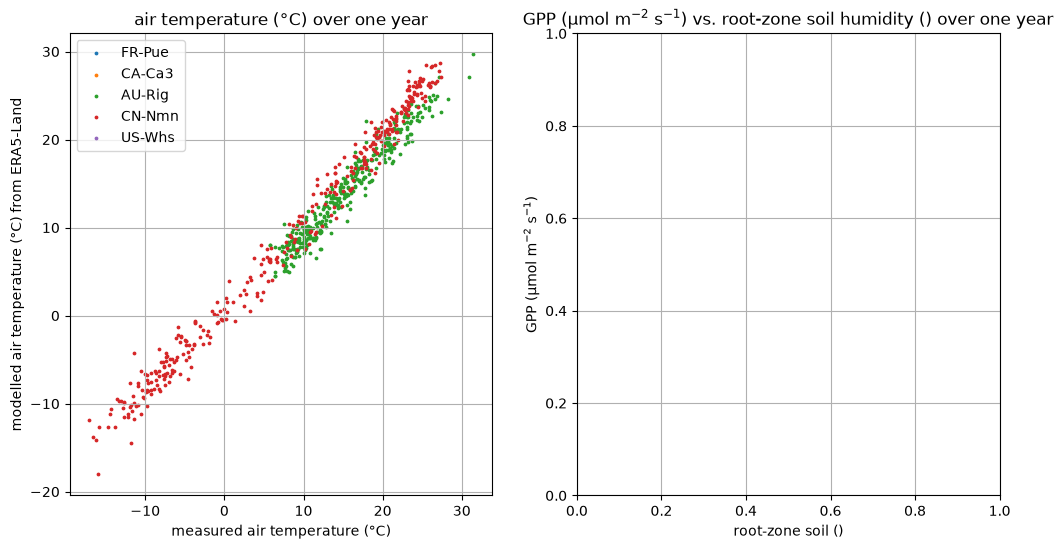

In [2]:
# ---- ERA5-Land ----

fig, ax = plt.subplots(1, 2, figsize=(12,6))

# Check: is ERA5-Land t2m close to the tower's TA_F? Plot one year of both.
for tower in site_static['site_id']:
    ax[0].scatter(
        site_daily['TA_F'][site_daily['site_id'] == tower][0:364], 
        site_daily['era5l_t2m_C'][site_daily['site_id'] == tower][0:364],
        label=tower,
        s=3
    )
del tower
ax[0].set_xlabel('measured air temperature (°C)')
ax[0].set_ylabel('modelled air temperature (°C) from ERA5-Land')
ax[0].grid()
ax[0].set_title('air temperature (°C) over one year')
ax[0].legend()

# Does GPP drop when the root-zone soil (swvl2, swvl3) dries out?
#Note: couldn't find variables 'swvl2' or 'swvl3'
ax[1].set_xlabel('root-zone soil ()')
ax[1].set_ylabel('GPP ($\\rm \\mu mol~m^{-2}~s^{-1}$)')
ax[1].grid()
ax[1].set_title('GPP ($\\rm \\mu mol~m^{-2}~s^{-1}$) vs. root-zone soil humidity () over one year')

plt.show()

**Observation**: measured and modelled air temperature seem to be very similar for all selected sites; however at several stations, there is an insufficient amount of available data for a reliable comparison.

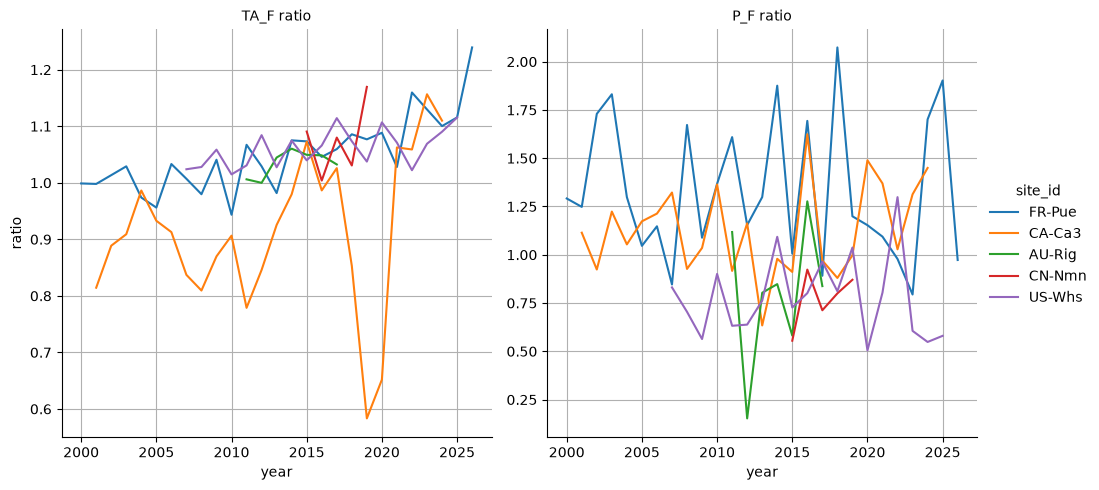

In [3]:
# ---- WorldClim ----
# Compare each tower year's mean TA_F and annual P_F with BIO1 and BIO12. Which of your years were unusually warm or dry?
airtemp_annual = {}
for tower in site_static['site_id']:
    airtemp_annual[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['TA_F'].mean() / site_static['BIO1'][site_static['site_id'] == tower].values

precip_annual = {}
for tower in site_static['site_id']:
    precip_annual[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['P_F'].sum() / site_static['BIO12'][site_static['site_id'] == tower].values

comparison_df = pd.DataFrame({
    'site_id': pd.concat(airtemp_annual).reset_index()['level_0'],
    'year': pd.concat(airtemp_annual).reset_index()['date'],
    'TA_F': pd.concat(airtemp_annual).reset_index()['TA_F'],
    'P_F': pd.concat(precip_annual).reset_index()['P_F']
})
comparison_df = pd.melt(
    comparison_df,
    id_vars=['site_id', 'year'],
    value_vars=['TA_F', 'P_F'],
    value_name='ratio',
    var_name='var'
)

del airtemp_annual
del precip_annual

g = sns.relplot(
    data=comparison_df, x='year', y='ratio',
    hue='site_id', col='var',
    kind='line', facet_kws={'sharey': False}
)
for ax in g.axes.flat:
    ax.grid(True)
g.set_titles('{col_name} ratio')
plt.show()

**Observation**: 2018-2020 were unusually cold at site 'CA-Ca3'; at site 'FR-Pue', there seems to be a positive trenf for the air temperature ratio over the years; unusually wet years occurred at site 'FR-Pue' several times, 2012 was unusually dry at site 'AU-Rig', and in 2016, all stations except for 'US-Whs' registered a one-year peak of relative wetness.

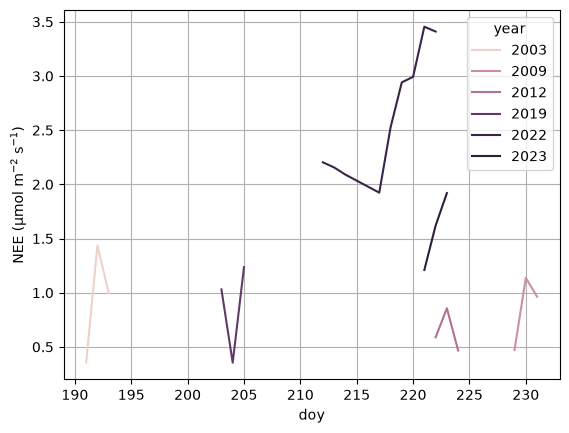

In [4]:
# ---- Dheed ----
# Pick an event at one of your towers. Was NEE less negative than in the same weeks of the other tower years?
dheed = site_daily[(site_daily['dheed_event'] == True) & (site_daily['site_id'] == site_static['site_id'].iloc[0])][['date', 'NEE_VUT_REF']]
dheed['doy'] = dheed['date'].dt.day_of_year
dheed['year'] = dheed['date'].dt.year

sns.lineplot(
    data=dheed,
    x='doy',
    y='NEE_VUT_REF',
    hue='year'
)
plt.grid()
plt.ylabel('NEE ($\\rm \\mu mol~m^{-2}~s^{-1}$)')
plt.show()

**Observation**: unfortunately, there is not really any time of year shared among the years of data available for this tower site when a Dheed event occurs and NEE data is available. For the other sites in this set, NEE coverage is even less for Dheed events. Therefore, the question cannot be properly answered. A week-wise comparison was not conducted here due to difficulties of implementing it.

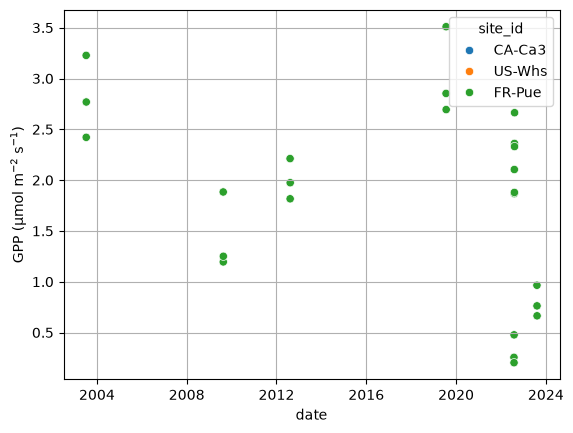

  site_id  soil0_30_clay  soil0_30_sand
0  FR-Pue      27.550000      30.966667
1  CA-Ca3      11.116667      51.050000
2  AU-Rig      20.700000      57.983333
3  CN-Nmn      18.383333      50.950000
4  US-Whs      20.783333      58.250000


In [17]:
# ---- SoilGrids ----
# Do the towers on sandy soils lose GPP faster in a dry spell than towers on clay?
soilgrids = site_daily[['site_id', 'date', 'GPP_NT_VUT_REF']][site_daily['dheed_event'] == True]

sns.scatterplot(data=soilgrids, x='date', y='GPP_NT_VUT_REF', hue='site_id')
plt.ylabel('GPP ($\\rm \\mu mol~m^{-2}~s^{-1}$)')
plt.grid()
plt.show()

print(site_static[['site_id', 'soil0_30_clay', 'soil0_30_sand']])

**Observation**: unfortunately, the lack in GPP data once again complicates the analysis. It is mostly available for the site 'FR-Pue' when there is a Dheed event. 'FR-Pue' has similar levels of clay and sand. Therefore, a valid comparison cannot be conducted for this set of towers.

In [ ]:
# ---- PlantTraits ----
# Across all 195 class towers: does leaf N or SLA explain the maximum daily GPP?
#Note: should we do that on the cluster? Data from 195 towers would be a lot, probably too much to handle on this computer.

In [ ]:
# ---- deadtrees.earth ----
# Forest towers in Europe: did standing deadwood rise after 2018, and did GPP or the GPP/EVI ratio fall with it?
#Note: what is the variable name of standing deadwood?

In [18]:
# ---- iNaturalist ----
# Phenology from people: in which week do the first flowering plants get photographed near your tower each spring, and does GPP start rising in the same week?
#Note: which variable describes whether/how many plants are flowering? From iNaturalist, there only seem to be yearly averages of observations contained in the merged dataset. From that alone, I'm afraid I'm unable to determine the season.

----------

## 2\) Provenance table

Per dataset: source, resolution, period, date accessed, citation

| Dataset | Source | Resolution | Period | Date accessed | Citation |
|---------|--------|------------|--------|---------------|----------|
| ERA5-Land | https://cds.climate.copernicus.eu | 9 km/0.1° | 1950-today | 2026-11-21 | Muñoz-Sabater et al. (2021) ESSD 13, 4349–4383, doi:10.5194/essd-13-4349-2021. Contains modified Copernicus Climate Change Service information (2026) |
| WorldClim 2.1 | https://worldclim.org | 5\' | 1970-2000 | 2026-11-21 | Fick & Hijmans (2017) Int. J. Climatol. 37, 4302–4315, doi:10.1002/joc.5086 |
| Dheed | https://doi.org/10.5281/zenodo.14884254 | 0.25°/daily | 1950–2023 | 2026-11-21 | Weynants et al. (2025) ESSD 17, 6621, doi:10.5194/essd-17-6621-2025. Data: doi:10.5281/zenodo.14884254 |
| SoilGrids 2.0 (ISRIC) | https://rest.isric.org | 250 m | - | 2026-11-21 | Poggio et al. (2021) SOIL 7, 217–240, doi:10.5194/soil-7-217-2021 |
| planttraits.earth | https://planttraits.earth | 1 km | - | 2026-11-21 | Lusk et al. (2026) Nat. Commun. 17, 1203, doi:10.1038/s41467-026-68996-y. Data: doi:10.5281/zenodo.14646322 |
| deadtrees.earth | https://deadtrees.earth | 10 m | 2017–2025 | 2026-11-21 | Mosig et al. (2026) Remote Sens. Environ. 332, 115027, doi:10.1016/j.rse.2025.115027 |
| iNaturalist | https://inaturalist.org | - | - | 2026-11-21 | iNaturalist contributors, iNaturalist (2026), https://www.inaturalist.org, accessed 21/11/2026 |
| MODIS Terra MOD13Q1 (Collection 6.1) | https://doi.org/10.5067/MODIS/MOD13Q1.061 | 250 m/16 d | 2000-today | 2026-11-22 | Didan (2021) MOD13Q1 V061, NASA LP DAAC, doi:10.5067/MODIS/MOD13Q1.061. ORNL DAAC (2018) MODIS Land Product Subsets Web Service, doi:10.3334/ORNLDAAC/1557 |

----------

## 3\) Site portrait

`site_static` as a table: climate, soil, traits, species records

In [19]:
#Note: the exact assignment seems unclear here. Is a markdown format table required? Which variables should be displayed? 'traits' is a very broad term and could mean any/all variable(s)

var_list = ['BIO1', 'BIO12', 'soil0_30_clay', 'soil0_30_sand', 'soil0_30_silt', 'n_species', 'n_plant_species']

print(round(site_static[var_list].set_index(site_static['site_id']), 2))

          BIO1   BIO12  soil0_30_clay  soil0_30_sand  soil0_30_silt  \
site_id                                                               
FR-Pue   13.64   674.0          27.55          30.97          41.45   
CA-Ca3    8.99  1532.0          11.12          51.05          37.87   
AU-Rig   15.15   601.0          20.70          57.98          21.33   
CN-Nmn    7.17   439.0          18.38          50.95          30.62   
US-Whs   16.86   376.0          20.78          58.25          20.92   

         n_species  n_plant_species  
site_id                              
FR-Pue      1055.0            439.0  
CA-Ca3       405.0            162.0  
AU-Rig        27.0             11.0  
CN-Nmn         NaN              NaN  
US-Whs       251.0             80.0  


**Site portrait**:

| site | BIO1 (°C) | BIO12 (mm) | soil0_30_clay (%) | soil0_30_sand (%) | soil0_30_silt (%) | n_species | n_plant_species |       
|------|-----------|------------|-------------------|-------------------|-------------------|-----------|-----------------|
| FR-Pue | 13.64 | 674.0 | **27.56** | 30.97 | **41.45** | **1055.0** | **439.0** |
| CA-Ca3 | 8.96 | **1532.0** | 11.12 | 51.05 | 37.87 | 405.0 | 162.0 |
| AU-Rig | 15.15 | 601.0 | 20.70 | 57.98 | 21.33 | 27.0 | 11.0 |
| CN-Nmn | 7.17 | 439.0 | 18.38 | 50.95 | 30.62 | `NaN` | `NaN` |
| US-Whs | **16.86** | 376.0 | 20.78 | **58.25** | 20.92 | 251.0 | 80.0 |


----------

## 4\) Time series

NDVI and EVI (yours vs MODIS) with GPP, one panel per tower

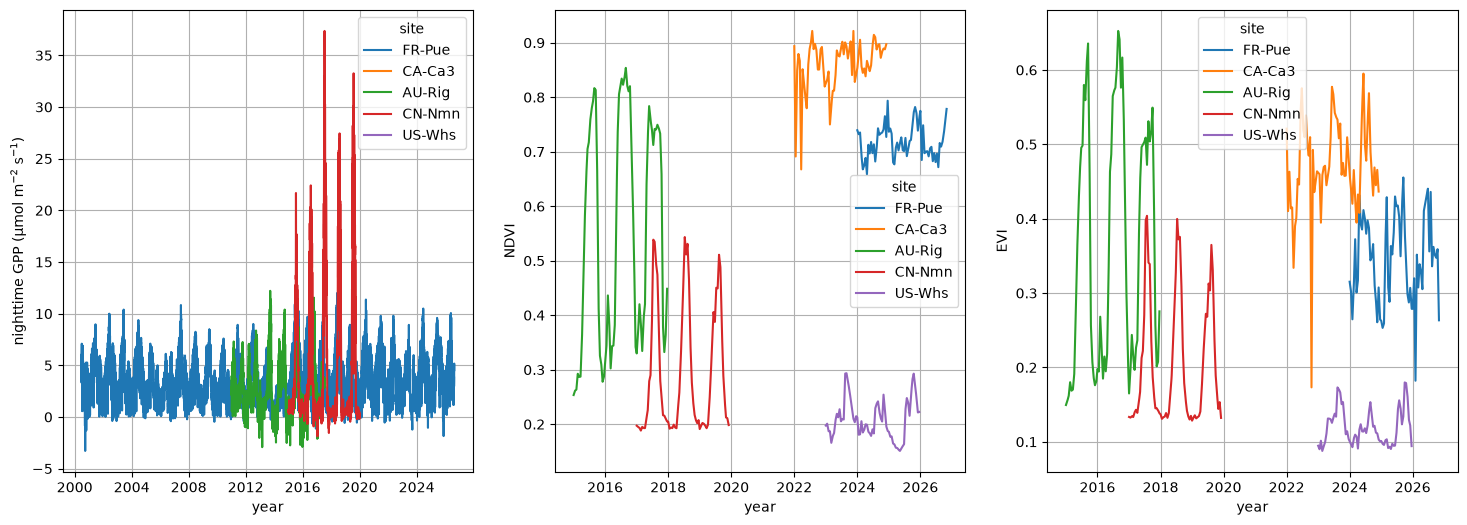

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18,6))

for tower in site_static['site_id']:
    ax[0].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['GPP_NT_VUT_REF'],
        label=tower
    )
del tower
ax[0].legend(title='site')
ax[0].grid()
ax[0].set_xlabel('year')
ax[0].set_ylabel('nighttime GPP ($\\rm \\mu mol~m^{-2}~s^{-1}$)')

for tower in site_static['site_id']:
    ax[1].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['ndvi'],
        label=tower
    )
del tower
ax[1].legend(title='site')
ax[1].grid()
ax[1].set_xlabel('year')
ax[1].set_ylabel('NDVI')

for tower in site_static['site_id']:
    ax[2].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['evi'],
        label=tower
    )
del tower
ax[2].legend(title='site')
ax[2].grid()
ax[2].set_xlabel('year')
ax[2].set_ylabel('EVI')

plt.show()

**Observation**: unfortunately, there is not a major overlap of GPP and NDVI/EVI data availability. From the limited data, no obvious connection between GPP and NDVI/EVI is visible. NDVI and EVI show fairly similar time series.

----------

## 5\) One question

Pick one of the six; one figure + 5–8 sentences, with n stated

*My question*:

(4) **Normal or not?** Annual TA_F and P_F of each tower year minus WorldClim BIO1 and BIO12.

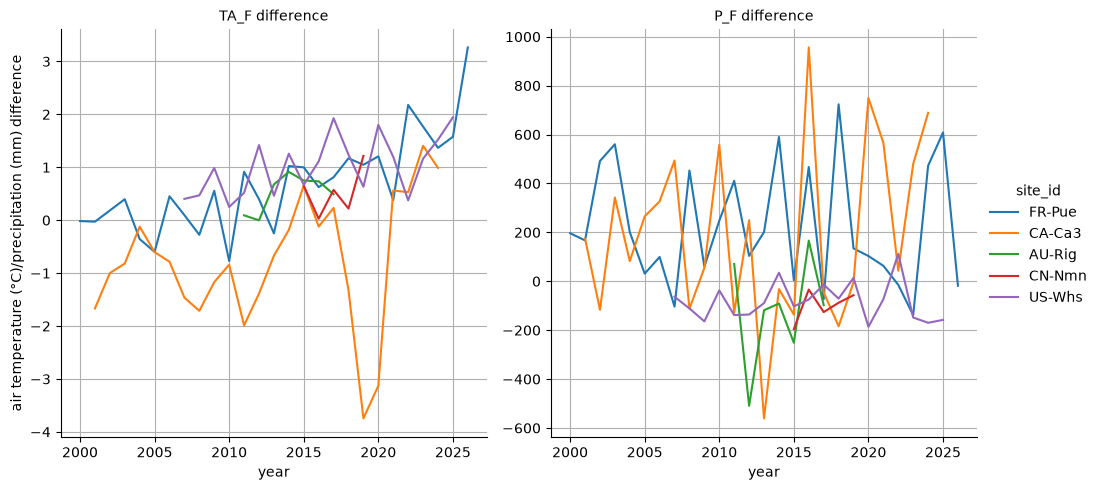

In [51]:
TA_diff = {}
for tower in site_static['site_id']:
    TA_diff[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['TA_F'].mean() - site_static['BIO1'][site_static['site_id'] == tower].values

P_diff = {}
for tower in site_static['site_id']:
    P_diff[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['P_F'].sum() - site_static['BIO12'][site_static['site_id'] == tower].values

comparison_df = pd.DataFrame({
    'site_id': pd.concat(TA_diff).reset_index()['level_0'],
    'year': pd.concat(TA_diff).reset_index()['date'],
    'TA_F': pd.concat(TA_diff).reset_index()['TA_F'],
    'P_F': pd.concat(P_diff).reset_index()['P_F']
})
comparison_df = pd.melt(
    comparison_df,
    id_vars=['site_id', 'year'],
    value_vars=['TA_F', 'P_F'],
    value_name='diff',
    var_name='var'
)

del TA_diff
del P_diff

g = sns.relplot(
    data=comparison_df, x='year', y='diff',
    hue='site_id', col='var',
    kind='line', facet_kws={'sharey': False}
)
for ax in g.axes.flat:
    ax.grid(True)
g.set_ylabels('air temperature (°C)/precipitation (mm) difference')
g.set_titles('{col_name} difference')
plt.show()

**Observation**: these results are essentially what was shown at the start (question for dataset 'WorldClim'), just with the variables now in their respective unit as these are differences and not ratios.

----------

## 6\) Scale

Per dataset: pixel vs footprint, and what that means for your answer

**Footprint size**: 100 m - 1 km

**Finer than the footprint**:

| Dataset | Pixel size |
|---------|------------|
| deadtrees.earth | 10 m |

-> *Consequence*: requires averaging (loss of information), but overall definitely better than coarse data

**Similar to footprint**:

| Dataset | Pixel size |
|---------|------------|
| MODIS MOD13Q1 | 250 m |
| SoilGrids | 250 m |
| PlantTraits | 1,000 m |

**Coarser than the footprint**:

| Dataset | Pixel size |
|---------|------------|
| WorldClim (5') | 9,000 m |
| ERA5-Land | 9,000 m |
| ERA5 / Dheed | 28,000 m |

-> *Consequence*: data contained also covers greater surroundings of the tower with potentially very different conditions (therefore not representative)